# 04_03 – Покрытие и временная согласованность C40

Исследуем все наблюдаемые полеты, включая специальные; прогноз предполагается при входе C40. Агрегаты относятся к записанным меткам, а не к независимо подтвержденным эксплуатационным событиям. Отбор не применяем.

Текущая таблица позволяет проверить порядок времен и возможное повторное присоединение, но не подтверждает однозначно правильный вход C40 по полной траектории. Геометрия и исторические опорные точки аэропортов отдельно не проверены. Сегмент перевозок не равен подтвержденному назначению полета. Полные группы с числом строк и меток сохраняются в CSV.

In [1]:
# Находим проект и подключаем анализ с проверкой входной копии
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'europe/data/source/osn23_landings_merged.parquet.gzip').exists())
sys.path.insert(0,str(ROOT / 'europe/scripts'))
import audit_c40_coverage as analysis

# Полный проход сохраняет агрегаты, временные проверки и контрольную сумму
coverage = analysis.main()
display(coverage['airport'])

{
  "input_sha256": "ddf11438bab44137242ffcf4da928418e116efd46defce58dc8a388b67942b6d",
  "input_unchanged": true,
  "rows_checked": 7984254,
  "go_arounds": 26253,
  "rows_changed": 0,
  "rows_deleted": 0,
  "present_c40_rows": 6331872,
  "c40_equal_to_first_attempt_rows": 0,
  "c40_before_first_attempt_rows": 6331785,
  "first_attempt_minus_c40_minutes": {
    "min": -44.81666666666667,
    "p05": 10.366666666666667,
    "median": 14.3,
    "p95": 22.033333333333335,
    "max": 135.01666666666668
  },
  "grouping_time": "UTC month of final landing, retrospective grouping only",
  "market_segment_is_verified_flight_purpose": false,
  "trajectory_matching_verified": false
}


,airport,c40_group,rows,go_arounds,ga_percent,within_group_row_percent,within_group_positive_percent
0,EDDB,after_first_attempt,1,1,100.000000,0.000462,0.125156
1,EDDB,missing,68250,370,0.542125,31.511441,46.307885
2,EDDB,present_not_after_first,148337,428,0.288532,68.488097,53.566959
3,EDDF,after_first_attempt,6,6,100.000000,0.000930,0.277649
4,EDDF,missing,39893,268,0.671797,6.186103,12.401666
5,EDDF,present_not_after_first,604982,1887,0.311910,93.812967,87.320685
6,EDDM,after_first_attempt,2,2,100.000000,0.000401,0.130548
7,EDDM,missing,55993,236,0.421481,11.216412,15.404700
8,EDDM,present_not_after_first,443211,1294,0.291960,88.783188,84.464752
9,EGCC,missing,123858,485,0.391577,58.617409,61.314791


## Пропуски по аэропортам

Знаменатель каждой доли – все наблюдения данного аэропорта. Нулевое покрытие C40 может ограничивать эксперимент в точке C40, но само по себе не является основанием удалять аэропорт из исходной базы.

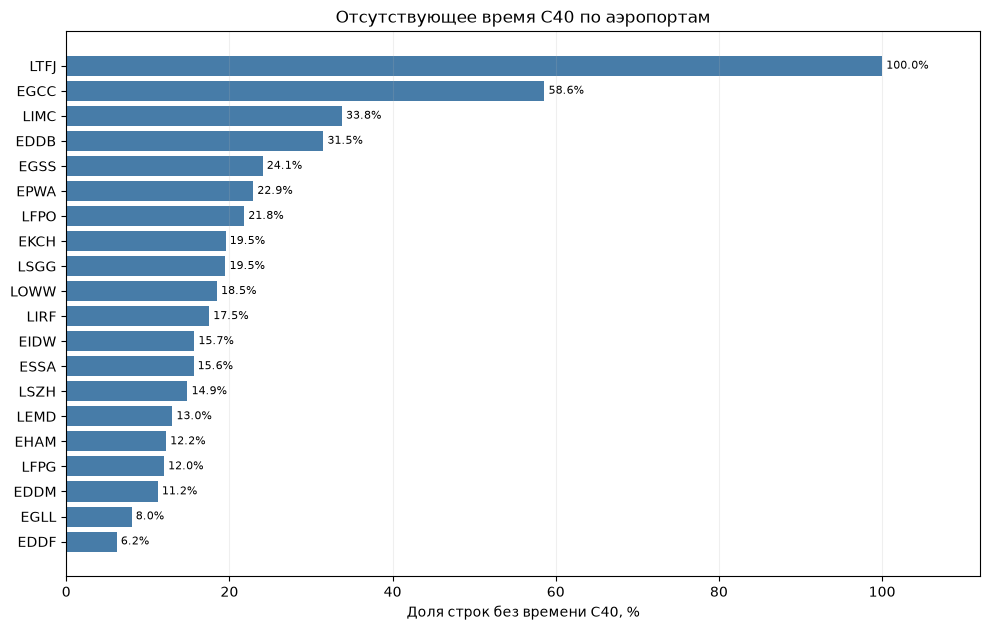

In [2]:
# Рисуем долю отсутствующего времени C40 по каждому аэропорту
analysis.missing_chart(coverage['airport'],'airport','04_03_airport_missing',
                       'Отсутствующее время C40 по аэропортам')
plt.show()

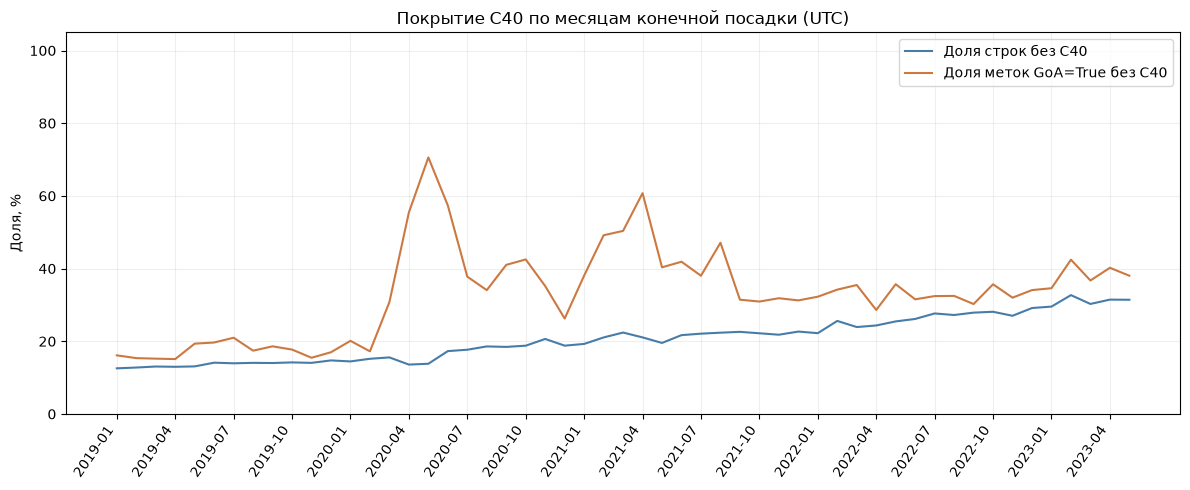

In [4]:
# Сравниваем покрытие строк и положительных меток по UTC-месяцам
analysis.monthly_chart(coverage['month'])
plt.show()

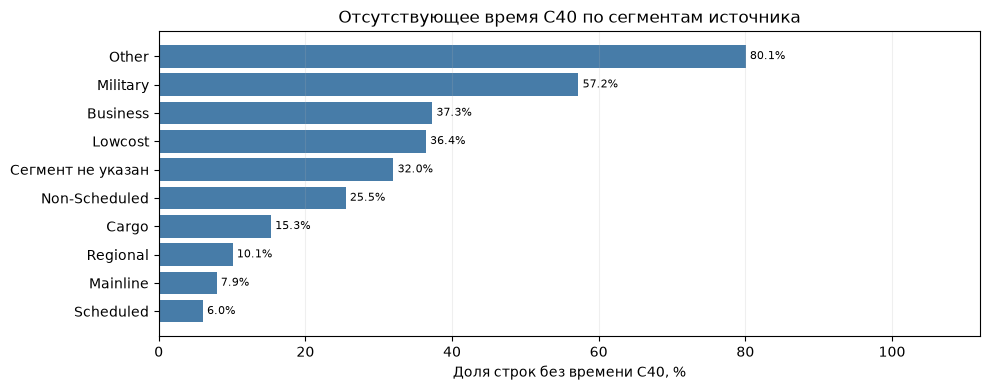

,market_segment,c40_group,rows,go_arounds,ga_percent,within_group_row_percent,within_group_positive_percent
0,Business,after_first_attempt,4,2,50.000000,0.001594,0.242131
1,Business,missing,93593,476,0.508585,37.306627,57.627119
2,Business,present_not_after_first,157278,348,0.221264,62.691779,42.130751
3,Cargo,after_first_attempt,7,4,57.142857,0.003050,0.518135
4,Cargo,missing,35167,118,0.335542,15.320842,15.284974
5,Cargo,present_not_after_first,194363,650,0.334426,84.676109,84.196891
6,Lowcost,after_first_attempt,33,5,15.151515,0.001876,0.087812
7,Lowcost,missing,641016,2400,0.374406,36.435482,42.149631
8,Lowcost,present_not_after_first,1118269,3289,0.294115,63.562642,57.762557
9,Mainline,after_first_attempt,25,23,92.000000,0.000772,0.218548


In [5]:
# Смотрим пропуски по сегментам, сохраняя отдельную группу null
analysis.missing_chart(coverage['market_segment'],'market_segment','04_03_segment_missing',
                       'Отсутствующее время C40 по сегментам источника')
plt.show()
display(coverage['market_segment'])

## Ограничения и следующий шаг

Данные сохранены, автоматически аэропорты и специальные полеты не исключаем. Отсутствующее C40 не восстанавливаем по итоговым временам. Различие частот между группами не доказывает влияние C40 на риск.

Дальше обсуждаем эксперимент в точке C40: определяем допустимость наблюдений и что делать с отсутствующими/неоднозначными отметками. Траекторное сопоставление, дополнительные источники и историческая геометрия требуют отдельной работы.

[Разбор результатов](../../reports/analytical_sample/04_03_review.md), [предыдущая карта признаков](04_02_feature_availability.ipynb), [разбор сопоставления C40](../../reports/preparation/06_c40_review.md).